
<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_08/4Yolo11_Detection_Image_Video_Pose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **YOLO11:**

A Ultralytics YOLO11 pode realizar diversas tarefas de visão computacional:

* **Deteção de objectos**: Identificação e localização de objectos em imagens ou fotogramas de vídeo, desenhando caixas delimitadoras (*bounding boxes*) à sua volta.
* **Segmentação de imagens:** Separação precisa dos contornos de cada objeto em nível de pixel, útil para aplicações como imagiologia médica e robótica.
* **Classificação**: Categorização de imagens inteiras com base no seu conteúdo visual.
* **Estimativa de pose**: Deteção de pontos-chave (*keypoints*) específicos numa imagem ou vídeo para seguir movimentos e posturas.
* **Deteção de objectos orientados (OBB)**: Deteção de objectos rotacionados com um ângulo de orientação adicionado, permitindo que ela acompanhe a inclinação exata do objeto.

A **detecção de pose** localiza uma pessoa com uma caixa delimitadora (*bounding box*) e dá a estimativa de pose identificando **pontos-chave anatômicos (*keypoints*)** — como olhos, ombros, cotovelos, punhos, quadris, joelhos e tornozelos (17 pontos no padrão COCO) — e os conecta formando um **esqueleto digital**. Em **vídeos**, a rede processa quadro a quadro (*frame-by-frame*), permitindo rastrear movimentos, gestos e posturas ao longo do tempo.

### 1. Instalação da Biblioteca `ultralytics`
Instalamos o pacote oficial **`ultralytics`**, que fornece acesso aos modelos pré-treinados da família **YOLO11**.

In [5]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


### 2. Download dos arquivos de exemplo (Vídeo e Imagem)

Baixamos um vídeo de frutas e vegetais (`.mp4`) e uma foto de cozinha (`.jpg`) para testar a inferência em diferentes formatos.

> Muitas imagens é vídeos gratuitos podem ser obtidos de **Pexels**, **Pixabay**, **Getty Images**.

In [1]:
!wget https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/yolo-data/fruit-and-vegetable-detection-short.mp4
!wget https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/yolo-data/green-farmhouse-kitchen.jpg



--2026-11-24 14:13:56--  https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_08/yolo-data/fruit-and-vegetable-detection-short.mp4
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/yolo-data/fruit-and-vegetable-detection-short.mp4 [following]
--2026-11-24 14:13:57--  https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/yolo-data/fruit-and-vegetable-detection-short.mp4
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7289313 (7.0M) [application/octet-stream]
Saving to: ‘fruit-and-vegetable-detection-short.mp4’

fruit-and-vegetabl

### 3. Importação da Classe `YOLO`
Importamos a classe principal `YOLO`, usada para carregar modelos pré-treinados e realizar previsões.

In [6]:
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### 4. Detecção de objetos em imagens
Primeiro, exibimos a imagem original da cozinha para referência visual.

In [7]:
import IPython
from IPython.display import Image, display

In [8]:
display(Image("/content/green-farmhouse-kitchen.jpg"))

#### Inferência com `yolo11n.pt`

Carregamos o modelo **`yolo11n.pt`** (*nano*, o mais leve e rápido; há também `s`, `m`, `l` e `x`). Com `model.predict(..., save=True)`, o modelo detecta os objetos e salva a saída anotada.


image 1/1 /content/green-farmhouse-kitchen.jpg: 640x640 2 cups, 11 bowls, 3 oranges, 1 chair, 3 potted plants, 1 oven, 436.4ms
Speed: 28.8ms preprocess, 436.4ms inference, 37.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


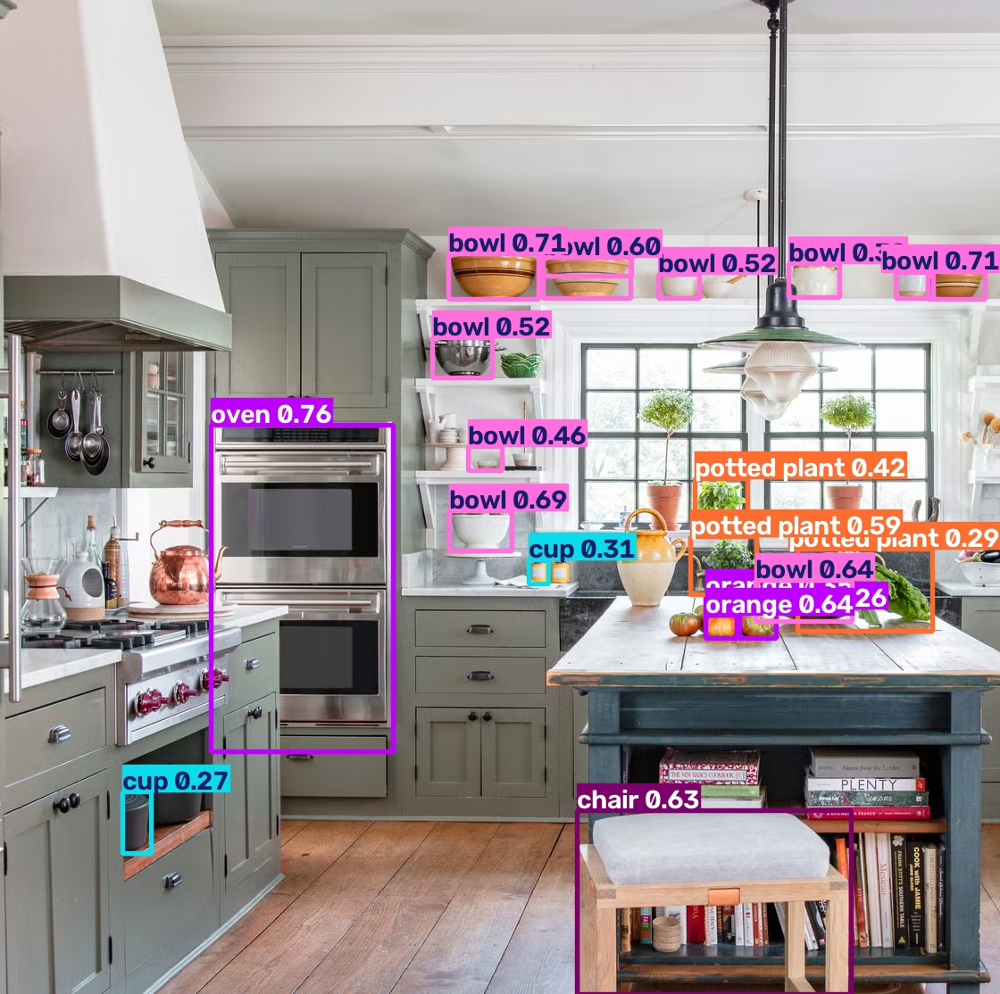

In [9]:
model = YOLO("yolo11n.pt")  # n, s, m, l, x versions available

results = model.predict(source="/content/green-farmhouse-kitchen.jpg", save=True)

results[0].show()

`results` é sempre uma **lista**:
* **1 imagem:** pegamos o primeiro item com `results[0]`.
* **Várias imagens ou vídeo:** cada frame/imagem vira um elemento (`results[0]`, `results[1]`, `results[2]`, ...).

**Atributos do `results[0]`:**
* **`boxes`**: caixas e previsões de cada objeto:
  * `boxes.xyxy`: coordenadas `[x1, y1, x2, y2]` em pixels.
  * `boxes.xywh`: centro `(x, y)` e tamanho `(largura, altura)`.
  * `boxes.conf`: confiança (*score*) da detecção.
  * `boxes.cls`: ID numérico da classe.
* **`names`**: traduz o ID da classe para o nome (ex.: `0` $\rightarrow$ `"person"`).

In [10]:
# lista objetos detectados e sua quantidade

results_list = []
for r in results:
    for c in r.boxes.cls:
        class_name = model.names[int(c)]
        results_list.append(class_name)

object_counts = {}
for obj in results_list:
    if obj in object_counts:
        object_counts[obj] += 1
    else:
        object_counts[obj] = 1

print("Objetos detectados e suas quantidades:")
for obj, count in object_counts.items():
    print(f"- {obj}: {count}")


Objetos detectados e suas quantidades:
- oven: 1
- bowl: 11
- orange: 3
- chair: 1
- potted plant: 3
- cup: 2


In [ ]:
display(Image("/content/runs/detect/predict/green-farmhouse-kitchen.jpg")) # check o diretório

### 5. Detecção de objetos em Vídeos

A mesma interface `YOLO(...)` permite processar **vídeos** (passando o caminho do `.mp4` em `source`). Cada predição de frame são retornado numa lista `results[0]`, `results[1]`, ..., `results[N]`

In [ ]:
from IPython.display import HTML
from base64 import b64encode

mp4 = open('/content/fruit-and-vegetable-detection-short.mp4','rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/477) /content/fruit-and-vegetable-detection-short.mp4: 384x640 5 apples, 1 orange, 155.6ms
video 1/1 (frame 2/477) /content/fruit-and-vegetable-detection-short.mp4: 384x640 5 apples, 120.9ms
video 1/1 (frame 3/477) /content/fruit-and-vegetable-detection-short.mp4: 384x640 5 apples, 1 orange, 136.8ms
video 1/1 (frame 4/477) /content/fruit-and-vegetable-detection-short.mp4: 384x640 4 apples, 1 orange, 128.4ms
video 1/1 (frame 5/477) /cont

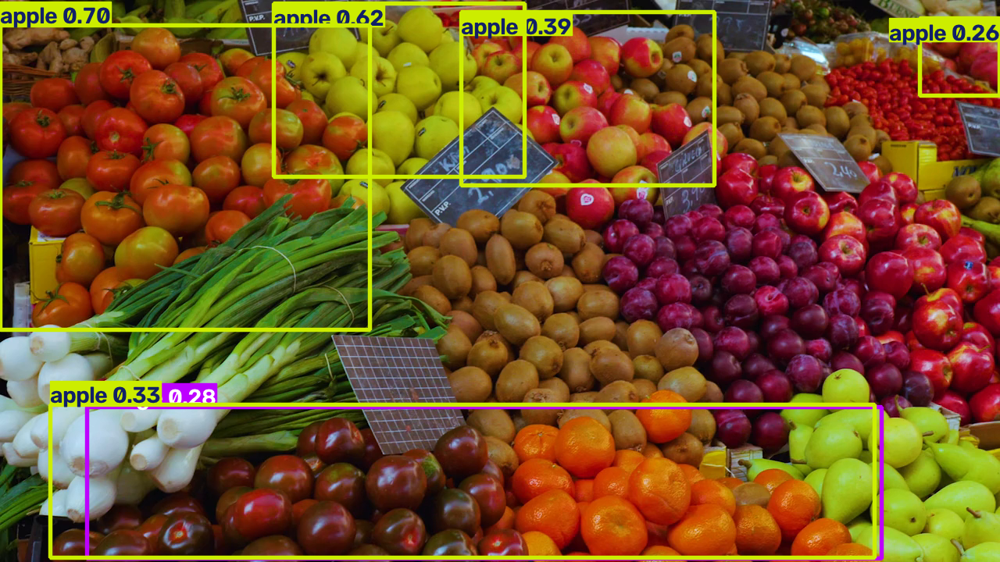

In [16]:
model = YOLO("yolo11n.pt")  # n, s, m, l, x versions available

results = model.predict(source='/content/fruit-and-vegetable-detection-short.mp4',save=True)

results[0].show()

Procure o arquivo .avi de resultado no diretório... o Colab pode ter problemas para exibir o vídeo

In [21]:
import subprocess

avi_path = "/content/runs/detect/predict-2/fruit-and-vegetable-detection-short.avi"
mp4_path = "/content/video_detectado.mp4"

# Converte para MP4 (H.264) compatível com o player do navegador
subprocess.run(
    ["ffmpeg", "-y", "-i", avi_path, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", mp4_path],
    check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
)


CompletedProcess(args=['ffmpeg', '-y', '-i', '/content/runs/detect/predict-2/fruit-and-vegetable-detection-short.avi', '-vcodec', 'libx264', '-crf', '23', '-preset', 'fast', '/content/video_detectado.mp4'], returncode=0)

In [22]:
from IPython.display import HTML
from base64 import b64encode

mp4 = open(mp4_path, "rb").read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

In [23]:
#for r in results:
#        boxes = r.boxes  # Boxes object for bbox outputs
#        masks = r.masks  # Masks object for segment masks outputs
#        probs = r.probs  # Class probabilities for classification outputs


In [24]:
results_list = []
for r in results:
    for c in r.boxes.cls:
        class_name = model.names[int(c)]
        results_list.append(class_name)

object_counts = {}
for obj in results_list:
    if obj in object_counts:
        object_counts[obj] += 1
    else:
        object_counts[obj] = 1

print("Objetos detectados e suas quantidades:")
for obj, count in object_counts.items():
    print(f"- {obj}: {count}")



Objetos detectados e suas quantidades:
- apple: 2781
- orange: 772
- banana: 2


### 6. Estimativa de Pose (*YOLO11-Pose*)

Ao trocar os pesos para **`yolo11n-pose.pt`**, o modelo deixa de fazer apenas detecção de objetos e passa a estimar **poses humanas** em duas etapas implícitas: localiza cada pessoa (`boxes`) e prevê **17 pontos-chave (*keypoints*)** anatômicos (rosto, ombros, cotovelos, punhos, quadris, joelhos e tornozelos).

* `results[0]` vem preenchido além de `r.boxes`, com `r.keypoints`:
  * `r.keypoints.xy`: coordenadas `(x, y)` em pixels de cada um dos 17 pontos por pessoa.
  * `r.keypoints.xyn`: mesmas coordenadas normalizadas (`0` a `1`).
  * `r.keypoints.conf`: confiança de cada ponto-chave (útil para ignorar articulações ocluídas ou fora do quadro).

* Neste exemplo usamod a imagem de *bus* do dataset da Ultralytics.

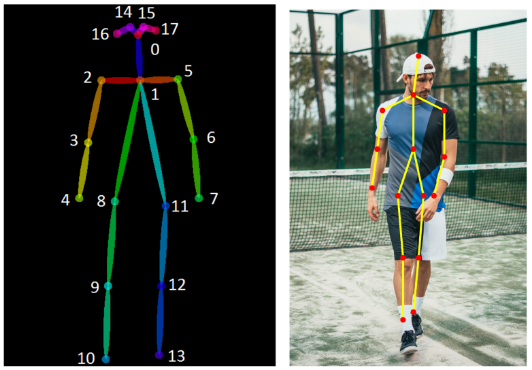

In [25]:
from ultralytics import YOLO

# Load a model
model = YOLO("yolo11n-pose.pt")  # load an official model

# Predict with the model
results = model("https://ultralytics.com/images/bus.jpg",save=True)  # predict on an image

# Access the results
# for result in results:
#    xy = result.keypoints.xy  # x and y coordinates
#    xyn = result.keypoints.xyn  # normalized
#    kpts = result.keypoints.data  # x, y, visibility (if available)
# ...


image 1/1 /content/bus.jpg: 640x480 4 persons, 206.2ms
Speed: 4.8ms preprocess, 206.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/pose/predict


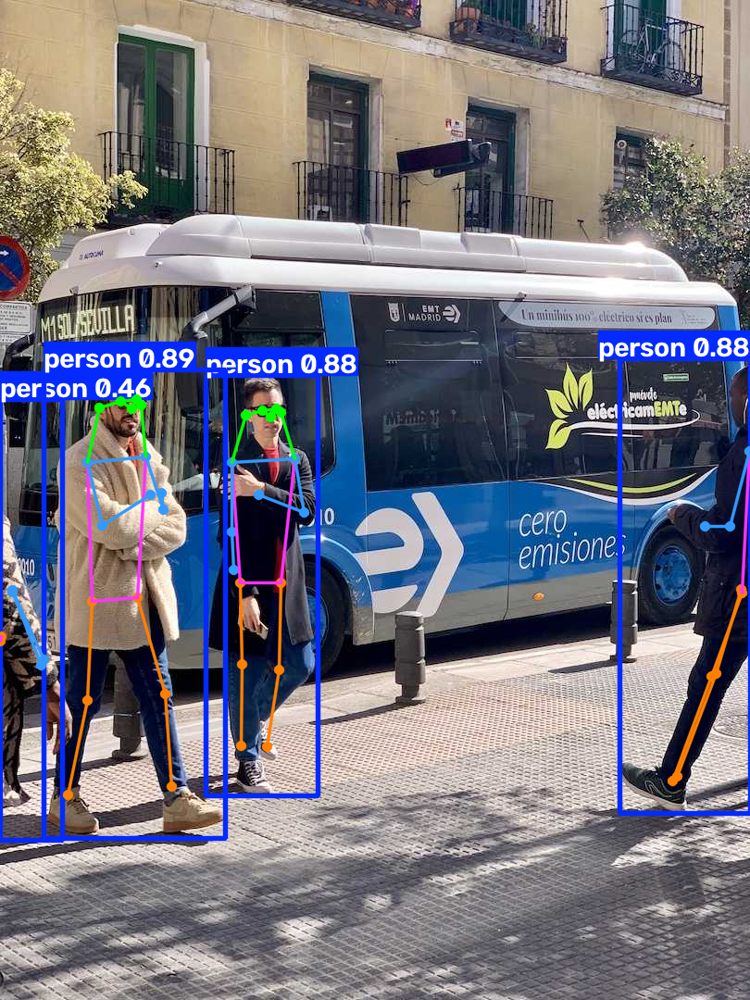

In [26]:
results[0].show()